In [2]:
import sys
from pathlib import Path

parent_dir = str(Path.cwd().parent)

if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

import numpy as np, matplotlib.pyplot as plt

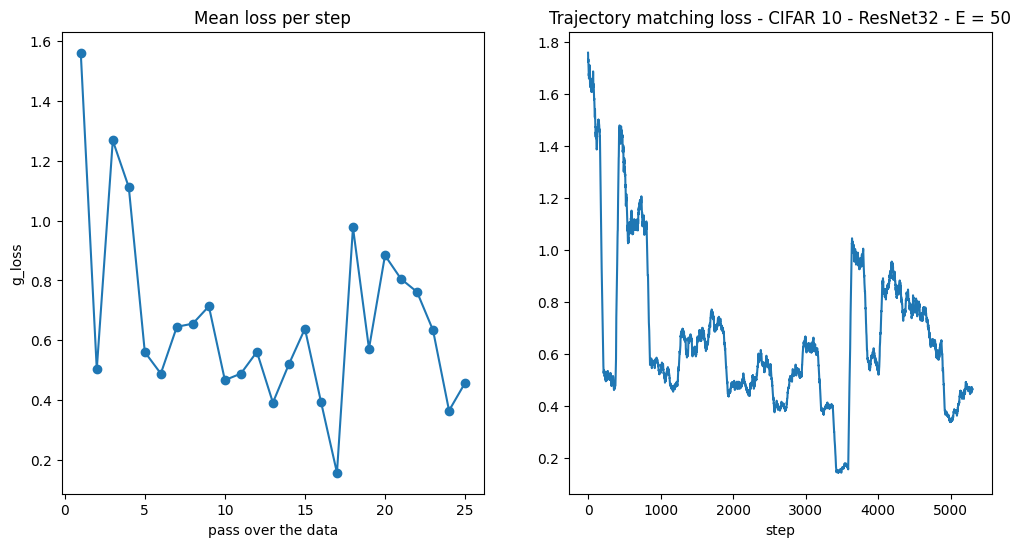

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

losses = np.load("../experiments/flip_c10_test2/losses.npy")
iters = 25                                  # the iterations value you used
steps = len(losses) // iters                # minibatches per pass (about 215)

per_pass = losses[: iters * steps].reshape(iters, steps).mean(axis=1)
axs[0].plot(range(1, iters + 1), per_pass, marker="o")
axs[0].set_xlabel("pass over the data"); axs[0].set_ylabel("mean matching loss")
axs[0].set_title('Mean loss per step')

axs[1].plot(np.convolve(np.load("../experiments/flip_c10_test2/losses.npy"), np.ones(50)/50, mode="valid"))
axs[1].set_xlabel("step"); axs[0].set_ylabel("g_loss")
axs[1].set_title('Trajectory matching loss - CIFAR 10 - ResNet32 - E = 50')

plt.show()

5350 214


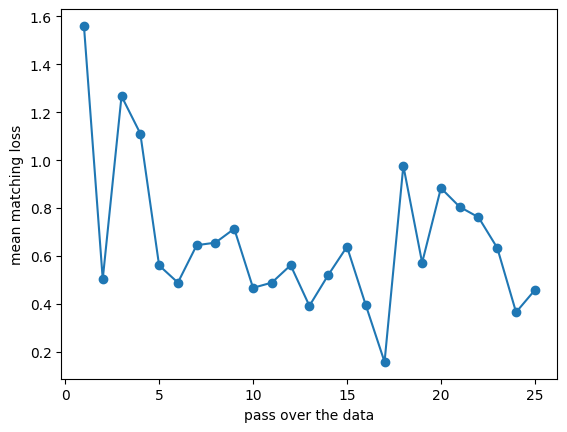

In [ ]:
import numpy as np, matplotlib.pyplot as plt



In [25]:
import numpy as np
import pandas as pd

d = "../experiments/flip_c10_test2/"
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
n_classes = len(classes)

def flip_table(budget):
    true = np.load(d + "true.npy").argmax(1)              # original class of each image
    new  = np.load(f"{d}{budget}.npy").argmax(1)          # hard label after flipping

    # one flat index per example, so a single bincount builds the whole matrix
    counts = np.bincount(true * n_classes + new, minlength=n_classes**2)
    M = counts.reshape(n_classes, n_classes)               # rows = true class i, columns = new label j
    return M

M = flip_table(1000)

In [26]:
pd.set_option("display.width", 250)
df = pd.DataFrame(M,
                  index=[f"true {c}" for c in classes],
                  columns=[f"-> {c}" for c in classes])
print(df)

                 -> airplane  -> automobile  -> bird  -> cat  -> deer  -> dog  -> frog  -> horse  -> ship  -> truck
true airplane           4983              0        2       0       15       0        0         0        0         0
true automobile            0           4977        0       0       16       0        1         0        0         6
true bird                  0              0     4984       0       16       0        0         0        0         0
true cat                   0              0        0    4981       19       0        0         0        0         0
true deer                  0              0        0       0     5000       0        0         0        0         0
true dog                   0              0        0       0       15    4985        0         0        0         0
true frog                  0              0        0       0       16       0     4984         0        0         0
true horse                 0              0        0       0       12   

In [27]:
for b in [150, 300, 500, 1000, 1500]:
    M = flip_table(b)
    np.fill_diagonal(M, 0)
    i, j = np.unravel_index(M.argmax(), M.shape)
    print(f"budget {b:>5}: {M.sum():>5} flips, most common {classes[i]} -> {classes[j]} ({M[i, j]})")

budget   150:   150 flips, most common truck -> deer (128)
budget   300:   300 flips, most common truck -> deer (247)
budget   500:   500 flips, most common truck -> deer (389)
budget  1000:  1000 flips, most common truck -> deer (683)
budget  1500:  1500 flips, most common truck -> deer (864)


Text(0.5, 1.0, 'Flipped labels - Budget = 1500')

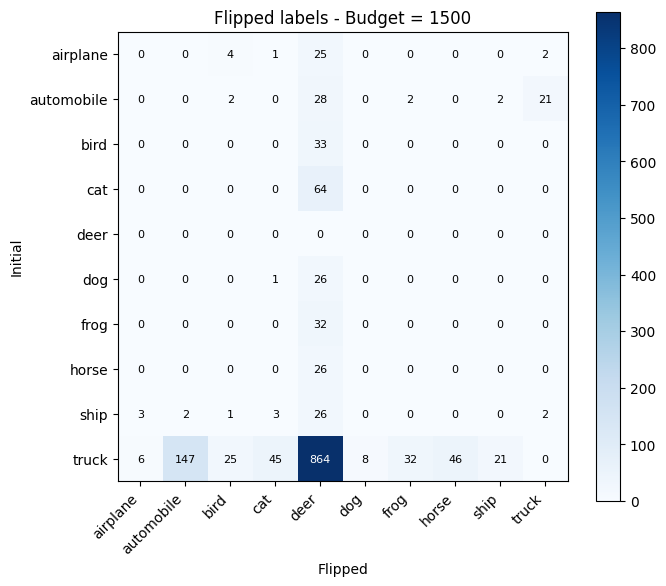

In [23]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(M, cmap="Blues")
ax.set_xticks(range(n_classes)); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(n_classes)); ax.set_yticklabels(classes)
ax.set_xlabel("Flipped"); ax.set_ylabel("Initial")
for i in range(n_classes):
    for j in range(n_classes):
        ax.text(j, i, int(M[i, j]), ha="center", va="center",
                color="white" if M[i, j] > M.max() / 2 else "black", fontsize=8)
fig.colorbar(im)
plt.tight_layout()
plt.title("Flipped labels - Budget = 1500")

(200, 2) (200, 2)


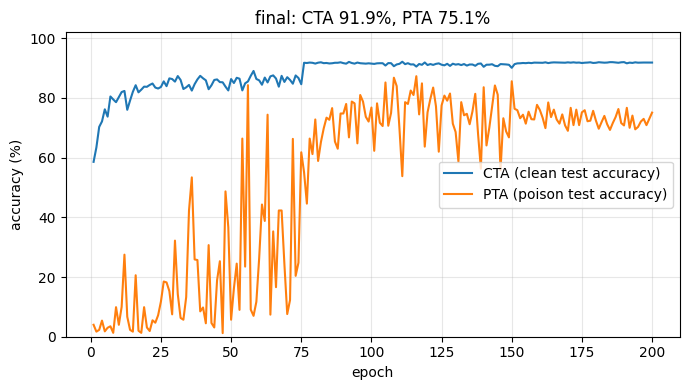

In [24]:
d = "../experiments/flip_c10_test2/user_500/0/"            # the user run's output_dir
cacc = np.load(d + "caccs.npy")                  # shape (epochs, 2): [accuracy, loss]
pacc = np.load(d + "paccs.npy")
print(cacc.shape, pacc.shape)

epochs = np.arange(1, len(cacc) + 1)             # epochs are numbered from 1

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, cacc[:, 0] * 100, label="CTA (clean test accuracy)")
ax.plot(epochs, pacc[:, 0] * 100, label="PTA (poison test accuracy)")
ax.set_xlabel("epoch"); ax.set_ylabel("accuracy (%)")
ax.set_ylim(0, 102); ax.grid(alpha=0.3); ax.legend(loc="center right")
ax.set_title(f"final: CTA {cacc[-1,0]*100:.1f}%, PTA {pacc[-1,0]*100:.1f}%")
plt.tight_layout(); plt.show()

|89.2/13.0|88.8/57.8|88.9/93.6|87.3/99.3|


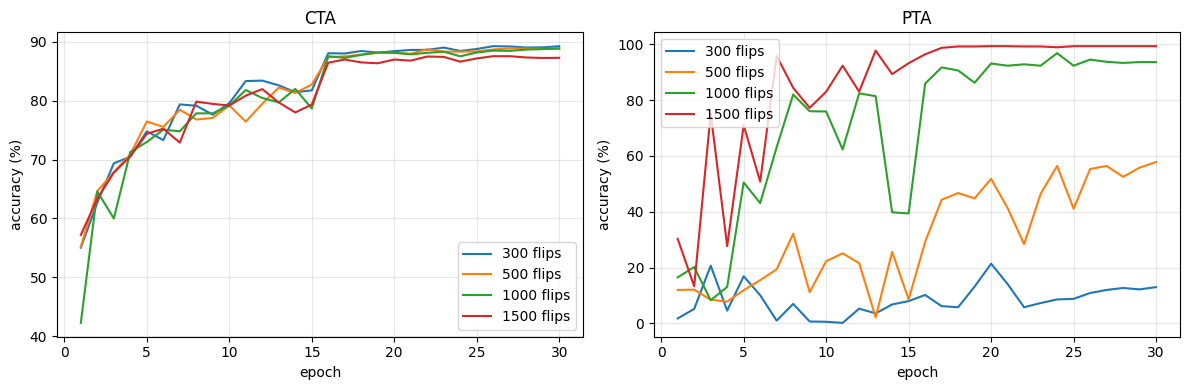

In [38]:
budgets = [300, 500, 1000, 1500]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

m = ""
cta = []
pta = []

for b in budgets:
    c = np.load(f"../experiments/flip_c10/user_{b}/caccs.npy")[:, 0] * 100
    p = np.load(f"../experiments/flip_c10/user_{b}/paccs.npy")[:, 0] * 100
    axes[0].plot(range(1, len(c) + 1), c, label=f"{b} flips")
    axes[1].plot(range(1, len(p) + 1), p, label=f"{b} flips")
    m+=f"|{c[-1]:.1f}/{p[-1]:.1f}"
    cta.append(c[-1])
    pta.append(p[-1])
    
m += "|"
print(m)

axes[0].set_title("CTA"); axes[1].set_title("PTA")
for a in axes:
    a.set_xlabel("epoch"); a.set_ylabel("accuracy (%)"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

Text(0.5, 1.0, 'CTA/PTA Tradeoff for ResNet-32 on CIFAR 10')

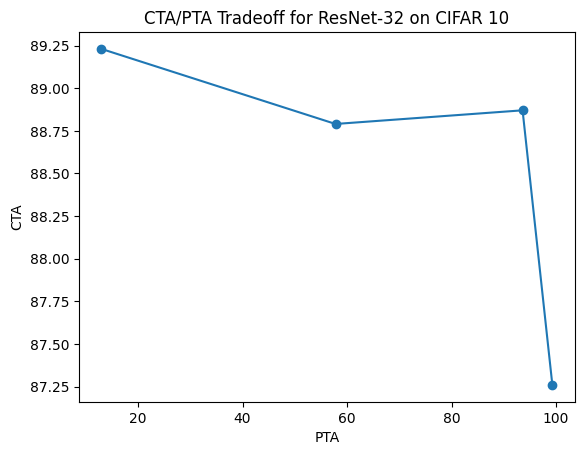

In [43]:
plt.plot(pta, cta, marker='o')
plt.xlabel('PTA')
plt.ylabel('CTA')
plt.title('CTA/PTA Tradeoff for ResNet-32 on CIFAR 10')

In [20]:
# reported results in the paper
original_cta = [92.26, 92.09, 91.73, 90.68, 89.87]
original_cta_std = [0.1, 0.1, 0.1, 0.1, 0.1]

original_pta = [12.4, 54.9, 87.2, 99.4, 99.8]
original_pta_std = [1.8, 2.4, 1.3, 0.2, 0.1]

data = np.genfromtxt('../experiments/flip_c10_test2/summary.csv', delimiter=',', names=True)

# 2. Extract the relevant columns
cta_mean = data['cta_mean']
cta_std  = data['cta_std']
pta_mean = data['pta_mean']
pta_std  = data['pta_std']
budget   = data['budget']

(89.0, 93.0)

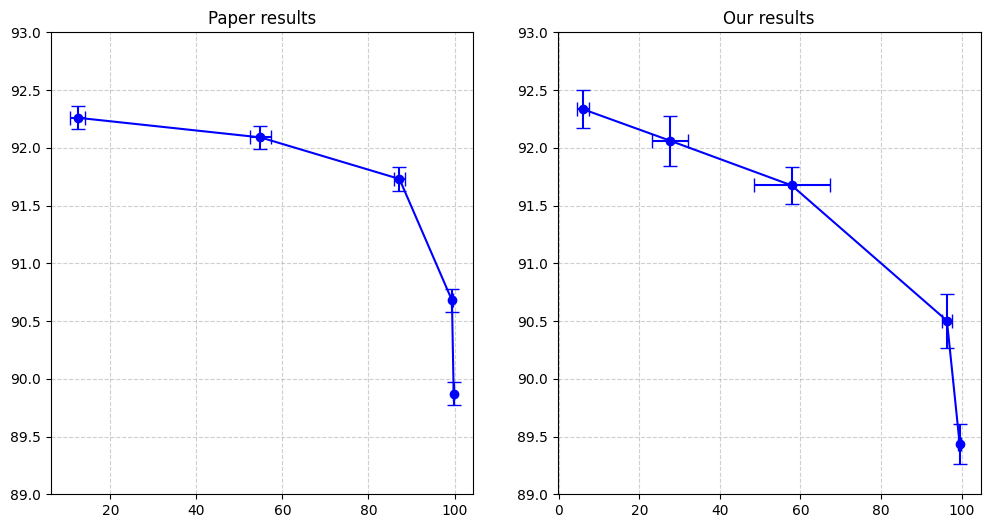

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].set_title('Paper results')
ax[0].errorbar(original_pta, original_cta, 
             xerr=original_pta_std, yerr=original_cta_std, 
             fmt='o', linestyle='-', capsize=5, color='blue',
             label='Data Points (with STD)')
ax[0].grid(True, linestyle='--', alpha=0.6)
ax[0].set_ylim(89, 93)


ax[1].set_title('Our results')
ax[1].errorbar(pta_mean, cta_mean, 
             xerr=pta_std, yerr=cta_std, 
             fmt='o', linestyle='-', capsize=5, color='blue',
             label='Data Points (with STD)')
ax[1].grid(True, linestyle='--', alpha=0.6)
ax[1].set_ylim(89, 93)
